# Regression from Scratch V3.0 (NumPy only) — Income, Gradient-Boosted Trees

**Version:** V3.0. **Role:** mandatory from-scratch twin of `regression_lightgbm_V3_0.ipynb` — no `lightgbm`. `sklearn` ONLY for split/metrics (and the sanity check's reference tree).

**Parity promise:** same data/features/split/seed as the library notebook, no `StandardScaler`/target transform — trains directly on raw-$ `Income` (trees are scale-invariant). Hand-rolled CART-with-gradient/Hessian tree (shared design with the classification twin, parameterized only by per-sample `(g, h)`; here `g=pred-y, h=1` recovers plain residual fitting), row+column subsampling, early stopping on val RMSE (the library's own stopping metric). Ensemble → `./weights_V3_0/regression_scratch_gbm.json`.

In [1]:
import json, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

assert os.path.exists("weights_V3_0/regression_lightgbm_test_metrics.json"), "run regression_lightgbm_V3_0.ipynb first"
SEED = 42
np.random.seed(SEED)
boost_rng = np.random.RandomState(SEED)  # separate stream drives row/column subsampling
os.makedirs("weights_V3_0", exist_ok=True)


## 1. LOAD DATA (identical to `regression_lightgbm_V3_0.ipynb`)

In [2]:
df = pd.read_csv("marketing_campaign.csv", sep="\t")
df = df.drop(columns=["ID", "Z_CostContact", "Z_Revenue"])
df["Dt_Customer"] = pd.to_datetime(df["Dt_Customer"], format="%d-%m-%Y")
ref_date = df["Dt_Customer"].max()
df["Customer_Tenure_Days"] = (ref_date - df["Dt_Customer"]).dt.days
df["Age"] = 2014 - df["Year_Birth"]
df = df[~df["Year_Birth"].isin([1893, 1899, 1900])].copy()
df = df[df["Income"] != 666666].copy()  # drop $666,666 income outlier (same treatment as Year_Birth sentinels)
df["Marital_Status"] = df["Marital_Status"].replace({"Absurd": "Single", "YOLO": "Single", "Alone": "Single"})
df = df.dropna(subset=["Income"]).copy()
print("cleaned:", df.shape, "| Income median:", round(df["Income"].median()))

REG_FEATURES = [
    "NumCatalogPurchases", "MntMeatProducts", "MntWines", "NumWebVisitsMonth",
    "MntSweetProducts", "MntFruits", "NumWebPurchases", "MntGoldProds",
    "NumStorePurchases", "MntFishProducts", "Kidhome", "Age", "NumDealsPurchases",
]
X_full = df[REG_FEATURES].values
y_full = df["Income"].astype(float).values
print(f"features: {len(REG_FEATURES)} dims (all numeric)")

X_temp, X_test, y_temp, y_test = train_test_split(X_full, y_full, test_size=0.20, random_state=SEED)
print(f"train {X_temp.shape} test {X_test.shape} | y mean {y_full.mean():.0f} std {y_full.std():.0f}")

X_tr, X_val, y_tr, y_val = train_test_split(X_temp, y_temp, test_size=0.10, random_state=SEED)
print(f"train {X_tr.shape} val {X_val.shape} test {X_test.shape}")


cleaned: (2212, 28) | Income median: 51371
features: 13 dims (all numeric)
train (1769, 13) test (443, 13) | y mean 51959 std 21522
train (1592, 13) val (177, 13) test (443, 13)


## 2. From-scratch gradient boosting: one generic CART-with-gradient/Hessian tree

Same shared design as the classification twin, parameterized only by per-sample `(g, h)`. Split gain:
`gain = 0.5*[G_L^2/(H_L+lambda) + G_R^2/(H_R+lambda) - (G_L+G_R)^2/(H_L+H_R+lambda)]` over all (feature,
threshold-midpoint) candidates. Leaf value (Newton step): `-G/(H+lambda)`. Regression: `g_i = pred_i - y_i`,
`h_i = 1` — this recovers residual-fitting through the same g/h path.

In [3]:
def best_split(X, g, h, feat_idx, reg_lambda, min_leaf):
    """Exact-greedy split search: max gain over (feature, midpoint-threshold) candidates."""
    G_tot, H_tot = g.sum(), h.sum()
    parent = 0.5 * (G_tot ** 2 / (H_tot + reg_lambda))
    best_gain, best_feat, best_thresh = 0.0, None, None
    for f in feat_idx:
        order = np.argsort(X[:, f], kind="mergesort")
        xs, gs, hs = X[order, f], g[order], h[order]
        n = len(xs)
        if n < 2 * min_leaf:
            continue
        cG, cH = np.cumsum(gs), np.cumsum(hs)
        GL, HL = cG[:-1], cH[:-1]
        GR, HR = G_tot - GL, H_tot - HL
        left_n = np.arange(1, n); right_n = n - left_n
        valid = (xs[:-1] != xs[1:]) & (left_n >= min_leaf) & (right_n >= min_leaf)
        if not valid.any():
            continue
        gain = 0.5 * (GL ** 2 / (HL + reg_lambda) + GR ** 2 / (HR + reg_lambda)) - parent
        gain = np.where(valid, gain, -np.inf)
        idx = np.argmax(gain)
        if gain[idx] > best_gain:
            best_gain, best_feat = gain[idx], f
            best_thresh = (xs[idx] + xs[idx + 1]) / 2.0
    return best_feat, best_thresh, best_gain

def build_tree(X, g, h, feat_idx, reg_lambda, min_leaf, max_depth, depth=0):
    """Depth-wise CART. Leaf value = Newton step -G/(H+lambda)."""
    G, H = g.sum(), h.sum()
    leaf_val = -G / (H + reg_lambda)
    if depth >= max_depth or len(g) < 2 * min_leaf:
        return {"leaf": True, "value": float(leaf_val)}
    f, thresh, gain = best_split(X, g, h, feat_idx, reg_lambda, min_leaf)
    if f is None or gain <= 1e-12:
        return {"leaf": True, "value": float(leaf_val)}
    mask = X[:, f] <= thresh
    left = build_tree(X[mask], g[mask], h[mask], feat_idx, reg_lambda, min_leaf, max_depth, depth + 1)
    right = build_tree(X[~mask], g[~mask], h[~mask], feat_idx, reg_lambda, min_leaf, max_depth, depth + 1)
    return {"leaf": False, "feature": int(f), "threshold": float(thresh), "left": left, "right": right}

def tree_predict(node, X):
    if X.shape[0] == 0:
        return np.empty(0)
    if node["leaf"]:
        return np.full(X.shape[0], node["value"])
    out = np.empty(X.shape[0])
    mask = X[:, node["feature"]] <= node["threshold"]
    out[mask] = tree_predict(node["left"], X[mask])
    out[~mask] = tree_predict(node["right"], X[~mask])
    return out

# depth-wise max_depth=5 stands in for LightGBM's leaf-wise num_leaves=31 (both bound tree capacity similarly)
# min_samples_leaf=20 mirrors LightGBM's unoverridden min_child_samples default
MAX_DEPTH, MIN_SAMPLES_LEAF, REG_LAMBDA = 5, 20, 1.0
LEARNING_RATE, N_ROUNDS, PATIENCE = 0.05, 500, 50
ROW_SUBSAMPLE, COL_SUBSAMPLE = 0.8, 0.8  # mirrors LightGBM's subsample / colsample_bytree
print(f"max_depth={MAX_DEPTH} min_samples_leaf={MIN_SAMPLES_LEAF} reg_lambda={REG_LAMBDA} "
      f"lr={LEARNING_RATE} n_rounds={N_ROUNDS} patience={PATIENCE} row_sub={ROW_SUBSAMPLE} col_sub={COL_SUBSAMPLE}")


max_depth=5 min_samples_leaf=20 reg_lambda=1.0 lr=0.05 n_rounds=500 patience=50 row_sub=0.8 col_sub=0.8


## 3. Sanity check — tree-building math vs sklearn, hand-derived closed form, monotonic loss

In [4]:
# (A) one depth-2 tree on synthetic data must match sklearn's DecisionTreeRegressor exactly
#     (reg_lambda=0 reduces our gain formula to plain variance reduction, sklearn's own criterion)
from sklearn.tree import DecisionTreeRegressor
rng_chk = np.random.RandomState(0)
X_chk = rng_chk.randn(60, 3)
y_chk = 2 * X_chk[:, 0] - X_chk[:, 1] + 0.1 * rng_chk.randn(60)
g_chk, h_chk = -y_chk, np.ones(60)  # g=pred-y at pred=0, h=1 -> leaf=mean(y), matches sklearn's "squared_error"
my_tree = build_tree(X_chk, g_chk, h_chk, list(range(3)), reg_lambda=0.0, min_leaf=1, max_depth=2)
my_pred = tree_predict(my_tree, X_chk)
sk_tree = DecisionTreeRegressor(max_depth=2, min_samples_leaf=1).fit(X_chk, y_chk)
sk_pred = sk_tree.predict(X_chk)
diff_a = float(np.max(np.abs(my_pred - sk_pred)))
print(f"sanity A: max|our_tree - sklearn_tree| = {diff_a:.3e}")
assert diff_a < 1e-9, "sanity check A FAILED: tree split/leaf math disagrees with sklearn"

# (B) hand-derived 3-row/2-round toy (depth-0 stump, no subsampling) + 20-round monotonic training loss
y_toy = np.array([1.0, 2.0, 3.0]); X_toy = np.zeros((3, 1))
F0_toy, lr_toy = 0.0, 0.1
expected_F_after_round = [0.2, 0.38]  # round1 leaf=6/3=2 -> F=0.2; round2 leaf=5.4/3=1.8 -> F=0.38
F_toy = np.full(3, F0_toy)
toy_losses = []
for r in range(20):
    g_toy, h_toy = F_toy - y_toy, np.ones(3)
    stump = build_tree(X_toy, g_toy, h_toy, [0], reg_lambda=0.0, min_leaf=1, max_depth=0)
    F_toy = F_toy + lr_toy * tree_predict(stump, X_toy)
    if r < 2:
        assert abs(F_toy[0] - expected_F_after_round[r]) < 1e-9, \
            f"sanity check B FAILED: round {r+1} expected F={expected_F_after_round[r]} got {F_toy[0]}"
    toy_losses.append(float(np.mean((F_toy - y_toy) ** 2)))
assert all(toy_losses[i] >= toy_losses[i + 1] - 1e-12 for i in range(len(toy_losses) - 1)), \
    "sanity check B FAILED: training loss not monotonically non-increasing"
print(f"sanity B: closed-form F match (rounds 1-2 expect {expected_F_after_round}) | "
      f"20-round toy loss monotonic: {toy_losses[0]:.4f} -> {toy_losses[-1]:.4f}")
print("ALL SANITY CHECKS PASSED")


sanity A: max|our_tree - sklearn_tree| = 4.441e-16
sanity B: closed-form F match (rounds 1-2 expect [0.2, 0.38]) | 20-round toy loss monotonic: 3.9067 -> 0.7258
ALL SANITY CHECKS PASSED


## 4. Train — boosting loop (row+column subsampling, early stop on val RMSE)

In [5]:
n_tr, n_feat = X_tr.shape
n_sub_rows = max(MIN_SAMPLES_LEAF * 2, int(round(ROW_SUBSAMPLE * n_tr)))
n_sub_cols = max(1, int(round(COL_SUBSAMPLE * n_feat)))

F0 = float(y_tr.mean())
F_tr, F_val = np.full(n_tr, F0), np.full(len(y_val), F0)

trees = []
history = {"round": [], "train_metric": [], "val_metric": []}
best_val, best_round, wait = np.inf, 0, 0
for r in range(1, N_ROUNDS + 1):
    g_full = F_tr - y_tr
    h_full = np.ones(n_tr)

    row_idx = boost_rng.choice(n_tr, size=n_sub_rows, replace=False)
    col_idx = boost_rng.choice(n_feat, size=n_sub_cols, replace=False)
    tree = build_tree(X_tr[row_idx], g_full[row_idx], h_full[row_idx], col_idx,
                       REG_LAMBDA, MIN_SAMPLES_LEAF, MAX_DEPTH)
    trees.append(tree)

    F_tr = F_tr + LEARNING_RATE * tree_predict(tree, X_tr)
    F_val = F_val + LEARNING_RATE * tree_predict(tree, X_val)

    train_rmse = float(np.sqrt(np.mean((F_tr - y_tr) ** 2)))
    val_rmse = float(np.sqrt(np.mean((F_val - y_val) ** 2)))
    history["round"].append(r); history["train_metric"].append(train_rmse); history["val_metric"].append(val_rmse)

    if val_rmse < best_val - 1e-9:
        best_val, best_round, wait = val_rmse, r, 0
    else:
        wait += 1
        if wait >= PATIENCE:
            break
    if r == 1 or r % 25 == 0:
        print(f"round {r:03d} | train RMSE ${train_rmse:,.0f} | val RMSE ${val_rmse:,.0f} | best_round {best_round}")

trees = trees[:best_round]
print(f"early-stopped after {r} rounds | best_iteration (val RMSE) = {best_round}")


round 001 | train RMSE $20,591 | val RMSE $21,192 | best_round 1


round 025 | train RMSE $10,946 | val RMSE $10,036 | best_round 25


round 050 | train RMSE $8,714 | val RMSE $7,767 | best_round 50
round 075 | train RMSE $7,996 | val RMSE $7,355 | best_round 75


round 100 | train RMSE $7,684 | val RMSE $7,332 | best_round 89
round 125 | train RMSE $7,361 | val RMSE $7,353 | best_round 114


round 150 | train RMSE $7,171 | val RMSE $7,421 | best_round 114
early-stopped after 164 rounds | best_iteration (val RMSE) = 114


## 5. Save ensemble (hand-rolled JSON, human-inspectable) + history + test-set evaluation

In [6]:
ensemble = {
    "F0": F0,
    "learning_rate": LEARNING_RATE,
    "reg_lambda": REG_LAMBDA,
    "feature_cols": REG_FEATURES,
    "best_iteration": best_round,
    "trees": trees,
}
with open("weights_V3_0/regression_scratch_gbm.json", "w") as f:
    json.dump(ensemble, f)
print(f"saved {len(trees)} trees -> weights_V3_0/regression_scratch_gbm.json")

pd.DataFrame(history).to_csv("weights_V3_0/regression_scratch_history.csv", index=False)

F_test = np.full(X_test.shape[0], F0)
for t in trees:
    F_test = F_test + LEARNING_RATE * tree_predict(t, X_test)

test_mse = float(mean_squared_error(y_test, F_test))
metrics = {
    "test_loss_MSE_raw": round(test_mse, 1),
    "rmse": round(float(np.sqrt(test_mse)), 1),
    "mae": round(float(mean_absolute_error(y_test, F_test)), 1),
    "r2": round(float(r2_score(y_test, F_test)), 4),
    "n_test": int(len(y_test)), "seed": SEED, "best_iteration": int(best_round),
}
print(json.dumps(metrics, indent=2))
with open("weights_V3_0/regression_scratch_test_metrics.json", "w") as f:
    json.dump(metrics, f, indent=2)
for i in range(5):
    print(f"  pred={F_test[i]:.0f} true={y_test[i]:.0f}")


saved 114 trees -> weights_V3_0/regression_scratch_gbm.json
{
  "test_loss_MSE_raw": 84877500.6,
  "rmse": 9212.9,
  "mae": 5904.9,
  "r2": 0.8213,
  "n_test": 443,
  "seed": 42,
  "best_iteration": 114
}
  pred=68634 true=62450
  pred=34439 true=37235
  pred=67781 true=65492
  pred=41011 true=42618
  pred=29597 true=26997


## 6. Loss curve (train vs val RMSE per round)

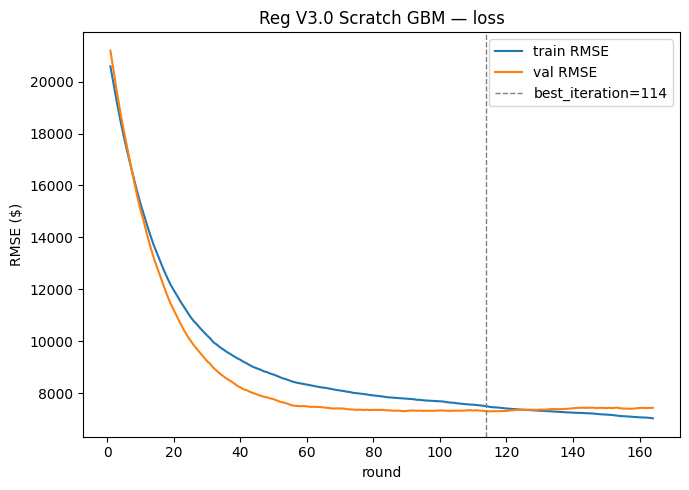

In [7]:
plt.figure(figsize=(7, 5))
plt.plot(history["round"], history["train_metric"], label="train RMSE")
plt.plot(history["round"], history["val_metric"], label="val RMSE")
plt.axvline(best_round, color="gray", linestyle="--", linewidth=1, label=f"best_iteration={best_round}")
plt.xlabel("round"); plt.ylabel("RMSE ($)"); plt.legend()
plt.title("Reg V3.0 Scratch GBM — loss")
plt.tight_layout()
plt.savefig("media/loss_reg_V3_0.png", dpi=150)
plt.show()


## 7. Parity check — scratch V3.0 vs LightGBM V3.0

In [8]:
lib = json.load(open("weights_V3_0/regression_lightgbm_test_metrics.json"))
scr = json.load(open("weights_V3_0/regression_scratch_test_metrics.json"))
for k in ("test_loss_MSE_raw", "rmse", "mae", "r2"):
    print(f"{k:<16}{lib[k]:>14}{scr[k]:>14}  absΔ={abs(scr[k]-lib[k]):.4f}")
rel_rmse = abs(scr["rmse"] - lib["rmse"]) / lib["rmse"]
d_r2 = abs(scr["r2"] - lib["r2"])
print("\nPARITY V3.0 (library vs scratch):", "PASS" if (rel_rmse < 0.10 and d_r2 < 0.05) else "FAIL")


test_loss_MSE_raw    84947282.4    84877500.6  absΔ=69781.8000
rmse                    9216.7        9212.9  absΔ=3.8000
mae                     5758.4        5904.9  absΔ=146.5000
r2                      0.8212        0.8213  absΔ=0.0001

PARITY V3.0 (library vs scratch): PASS
